# English–Urdu HTML Audit: Inline Language + RTL CSS
**Dataset:** `urdu_rtl_study.zip`, containing 480 HTML pages. This notebook adds two non-LLM evaluators missing from the original pipeline.

**Check A:** W3C WCAG 2.2 3.1.2 language-of-parts *screening*, based on English-like phrases and inherited `lang`; it is a review-candidate finder, **not a definitive violation detector**. Checks initial rendered DOM as well as source HTML.

**Check B:** Parse embedded and inline CSS declarations using `tinycss2` to compare direction-sensitive physical CSS with flow-relative logical CSS; **CSS style choice is not equivalent to a visible RTL failure**.

The English prompts request English output; Urdu prompts request Urdu output, so prompt language and localization are confounded. Outputs include CSVs, charts and a reviewer checklist.

In [1]:
%pip -q install beautifulsoup4 tinycss2 pandas numpy matplotlib playwright

In [2]:
!python -m playwright install chromium

199.3 MiB [] 0% 0.0s199.3 MiB [] 0% 37.2s199.3 MiB [] 0% 22.6s199.3 MiB [] 0% 17.1s199.3 MiB [] 1% 6.1s199.3 MiB [] 2% 3.5s199.3 MiB [] 3% 2.8s199.3 MiB [] 4% 2.5s199.3 MiB [] 5% 2.2s199.3 MiB [] 7% 2.0s199.3 MiB [] 8% 1.9s199.3 MiB [] 8% 2.1s199.3 MiB [] 8% 2.3s199.3 MiB [] 8% 2.5s199.3 MiB [] 10% 2.3s199.3 MiB [] 11% 2.2s199.3 MiB [] 12% 2.1s199.3 MiB [] 13% 2.0s199.3 MiB [] 14% 2.0s199.3 MiB [] 15% 1.9s199.3 MiB [] 16% 1.9s199.3 MiB [] 17% 1.9s199.3 MiB [] 18% 1.8s199.3 MiB [] 19% 1.8s199.3 MiB [] 20% 1.8s199.3 MiB [] 21% 1.8s199.3 MiB [] 22% 1.8s199.3 MiB [] 23% 1.8s199.3 MiB [] 24% 1.7s199.3 MiB [] 24% 1.8s199.3 MiB [] 24% 1.9s199.3 MiB [] 25% 1.8s199.3 MiB [] 27% 1.7s199.3 MiB [] 28% 1.7s199.3 MiB [] 29% 1.6s199.3 MiB [] 30% 1.6s199.3 MiB [] 31% 1.5s199.3 MiB [] 33% 1.5s199.3 MiB [] 34% 1.4s199.3 MiB [] 36% 1.3s199.3 MiB [] 37% 1.3s199.3 MiB [] 39% 1.2s199.3 MiB [] 40% 1.2s199.3 MiB [] 41% 1.2s199.3 MiB [] 42% 1.2s199.3 MiB [] 43% 1.1s199.3 MiB [] 44% 1.1s199.3 MiB [] 46% 1.0s199

## Upload the original dataset ZIP
Upload `urdu_rtl_study.zip`. The prompt workbook is not needed for these two checks.

In [3]:
from pathlib import Path
from google.colab import files
import shutil, pandas as pd, asyncio

if not Path('/content/urdu_rtl_study.zip').exists():
    print('Upload urdu_rtl_study.zip')
    uploaded = files.upload()
DATASET = '/content/urdu_rtl_study.zip'
OUTPUT = '/content/rtl_two_checks_results'
assert Path(DATASET).exists(), 'Please upload urdu_rtl_study.zip'

Upload urdu_rtl_study.zip


Saving urdu_rtl_study.zip to urdu_rtl_study.zip


## Step 1 — Deterministic source-HTML and CSS audit

In [4]:
%%writefile /content/rtl_language_css_audit.py
"""Non-LLM, conservative inline-language and direction-sensitive CSS audit.
Inputs: urdu_rtl_study.zip (480 HTML pages); optional metadata workbook not needed.
Outputs: per-page metrics, evidence CSVs, visualizations, and report.
This is a static audit of submitted HTML; no claim of WCAG conformance or rendering failures.
Requires beautifulsoup4, tinycss2, pandas, numpy, matplotlib.
"""
from __future__ import annotations
import re, json, csv, zipfile, hashlib, textwrap, argparse, collections
from pathlib import Path
from dataclasses import dataclass
from typing import Any

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tinycss2
from bs4 import BeautifulSoup, NavigableString, Tag, Comment, CData, Declaration, Doctype, ProcessingInstruction

URDU_RE = re.compile(r'[\u0600-\u06ff\u0750-\u077f\u08a0-\u08ff]')
LATIN_WORD = r"[A-Za-z]+(?:['’\-][A-Za-z]+)*"
LATIN_SPAN_RE = re.compile(rf"{LATIN_WORD}(?:[ \t\u00a0\u2009&:/;,().!?—–-]+{LATIN_WORD})*", re.UNICODE)
WORD_RE = re.compile(LATIN_WORD)
STOPWORDS = set('a an and are as at be been but by can could did do does for from had has have how i if in into is it its my of on or our please that the their them there these this those to up use was we were what when where which who why will with would you your click here read more go back sign log enter choose select add remove delete save cancel next previous start find show view see all us me now help get'.split())
ACTION_PHRASES = {'contact us','read more','learn more','sign in','log in','sign up','get started','click here','submit form','forgot password','reset password','create account','add task','open menu','close menu','view details','show more','load more','our services','contact support','back home','about us','send message'}
SKIP_TAGS = {'script','style','noscript','template','svg','math','code','pre','kbd','samp','textarea'}
HUMAN_ATTRS = {'aria-label','aria-description','placeholder','title','alt'}
IGNORED_EXACT = {'html','css','js','javascript','url','http','https','com','org','www','mailto'}

# Logical and physical classification is intentionally conservative. Direction-sensitive
# physical declarations indicate *risks requiring review*, not verified defects.
PHYSICAL_PROP_RE = re.compile(r'(?:^|[-])(left|right)(?:$|[-])')
LOGICAL_PROP_RE = re.compile(r'(?:^|[-])inline(?:$|[-])|^(?:inset-inline|margin-inline|padding-inline|border-inline|scroll-margin-inline|scroll-padding-inline)|^(?:border-start-start-radius|border-start-end-radius|border-end-start-radius|border-end-end-radius)$')
PHYSICAL_KEYWORD_RE = re.compile(r'(?<![-\w])(?:left|right)(?![-\w])',re.I)
LOGICAL_VALUE_RE = re.compile(r'(?<![-\w])(?:start|end|inline-start|inline-end)(?![-\w])',re.I)
SIDE_PROPS = {'text-align','float','clear','background-position','background-position-x','object-position','transform-origin','perspective-origin','caption-side'}
SHORTHAND_PROPS = {'margin','padding','border-width','border-color','border-style','scroll-margin','scroll-padding','border-radius'}


def nearest_lang(element: Tag|None) -> tuple[str,bool]:
    here = element
    while isinstance(here,Tag):
        lang = here.get('lang') or here.get('xml:lang')
        if lang:
            return str(lang).lower().split('-')[0], bool(here is element)
        here = here.parent
    return 'unknown', False


def cssish_selector(tag: Tag|None):
    if not isinstance(tag,Tag): return ''
    ident = ('#'+str(tag.get('id'))) if tag.get('id') else ''
    cls = ''.join('.'+c for c in tag.get('class',[])[:2])
    return (tag.name or '') + ident + cls


def phrase_type(text:str)->str:
    """High confidence English-like text != confirmed English-language WCAG violation."""
    w = [v.lower() for v in WORD_RE.findall(text)]
    if len(w)<2: return 'none'
    if re.search(r'(?i)(https?://|www\.|\b[a-z0-9.-]+\.(?:com|org|net|edu|gov|pk|io|example)\b|\b[A-Z]{2}/[A-Z]{2}\b|@)', text): return 'none'
    if re.fullmatch(r'[A-Za-z0-9._+-]+', text.strip()) and '.' in text: return 'none'  # identifiers/usernames
    w = [s for s in w if s not in IGNORED_EXACT]
    if len(w)<2: return 'none'
    s=' '.join(w)
    if any(t in s for t in ['http','www']): return 'none'
    if s in ACTION_PHRASES or (len(w)>=3 and sum(x in STOPWORDS for x in w)>=1):
        return 'high_confidence_phrase'
    return 'review_candidate'


def audit_inline_language(soup:BeautifulSoup, meta:dict) -> tuple[list[dict],dict]:
    evid=[]
    root=soup.html
    root_lang=nearest_lang(root)[0] if root else 'unknown'
    counter=collections.Counter()
    text_nodes=0
    # Content text (excludes markup such as script and SVG and hidden template nodes).
    for node in soup.descendants:
        if not isinstance(node,NavigableString) or isinstance(node,(Comment,CData,Declaration,Doctype,ProcessingInstruction)): continue
        tag=node.parent
        if not isinstance(tag,Tag): continue
        if any(isinstance(p,Tag) and p.name in SKIP_TAGS for p in [tag,*list(tag.parents)]):continue
        if tag.name in {'head','title'}:continue
        if any(isinstance(p,Tag) and p.has_attr('hidden') for p in [tag,*list(tag.parents)]):continue
        val=str(node)
        if not val.strip():continue
        text_nodes+=1
        for match in LATIN_SPAN_RE.finditer(val):
            phrase=match.group().strip(' \t.,:;!?()—–-')
            conf=phrase_type(phrase)
            if conf=='none':continue
            lang,_=nearest_lang(tag)
            # Compare only foreign text in Urdu documents, or Urdu in English page via companion audit.
            if root_lang != 'ur':continue
            if URDU_RE.search(phrase): continue
            marked=lang=='en'
            evid.append({**meta,'source':'text','tag':cssish_selector(tag),'phrase':phrase[:180],
                'classification':conf,'effective_lang':lang,'lang_en_present':int(marked),
                'requires_review':int(not marked),'mixed_script_text_node':int(bool(URDU_RE.search(val))),
                'caveat':'Candidate; human language/exceptions must be verified'})
    for tag in soup.find_all(True):
        if tag.name in SKIP_TAGS or tag.has_attr('hidden'): continue
        for attr in HUMAN_ATTRS:
            val=tag.get(attr)
            if not isinstance(val,str) or not val.strip():continue
            for match in LATIN_SPAN_RE.finditer(val):
                phrase=match.group().strip(' \t.,:;!?()—–-')
                conf=phrase_type(phrase)
                if conf=='none' or root_lang!='ur':continue
                lang,_=nearest_lang(tag)
                marked=lang=='en'
                evid.append({**meta,'source':f'attribute:{attr}','tag':cssish_selector(tag),'phrase':phrase[:180],
                    'classification':conf,'effective_lang':lang,'lang_en_present':int(marked),
                    'requires_review':int(not marked),'mixed_script_text_node':int(bool(URDU_RE.search(val))),
                    'caveat':'Candidate; human language/exceptions must be verified'})
    for e in evid:
        counter['lang_phrase_candidates']+=1
        counter['lang_marked_en']+=e['lang_en_present']
        counter['lang_unmarked']+=e['requires_review']
        counter['lang_high_confidence']+=int(e['classification']=='high_confidence_phrase')
        counter['lang_high_confidence_unmarked']+=int(e['classification']=='high_confidence_phrase' and e['requires_review'])
        counter['lang_mixed_script_candidates']+=e['mixed_script_text_node']
        counter['lang_attribute_candidates']+=int(e['source'].startswith('attribute:'))
    counter['explicit_en_language_elements']=len(soup.find_all(lambda x:isinstance(x,Tag) and str(x.get('lang','')).lower().startswith('en')))
    counter['text_nodes_scanned']=text_nodes
    return evid,dict(counter)


def serialized_value(tokens):
    return tinycss2.serialize(tokens).strip()


def split_css_shorthand(value):
    """Only flag 4-value physical shorthands whose opposing sides differ."""
    # enough for literal values; var() and calc() conservatively treated as unevaluable
    if any(ch in value for ch in '()') : return []
    parts=value.split()
    return parts


def classify_decl(prop:str,value:str)->str:
    prop=prop.lower().strip()
    if prop.startswith('--'):return 'neutral'
    if LOGICAL_PROP_RE.search(prop):return 'logical'
    if PHYSICAL_PROP_RE.search(prop):return 'physical_property'
    if prop in SIDE_PROPS:
        if PHYSICAL_KEYWORD_RE.search(value):return 'physical_value'
        if LOGICAL_VALUE_RE.search(value):return 'logical'
    if prop in SHORTHAND_PROPS:
        p=split_css_shorthand(value.lower())
        if len(p)==4 and ((p[1]!=p[3]) or (prop=='border-radius' and p[0]!=p[2])):
            return 'asymmetric_physical_shorthand'
    return 'neutral'


def traverse_rules(rules:list,mode:str='stylesheet',selector:str='',context:str=''):
    for rule in rules:
        if rule.type=='qualified-rule':
            sel=serialized_value(rule.prelude)
            ds=tinycss2.parse_declaration_list(rule.content,skip_whitespace=True,skip_comments=True)
            for d in ds:
                if d.type=='declaration':yield (sel,context,d)
        elif rule.type=='at-rule' and rule.content is not None:
            atr='@'+str(rule.lower_at_keyword)
            if atr in {'@media','@supports','@layer','@container','@document','@scope'}:
                yield from traverse_rules(tinycss2.parse_rule_list(rule.content,skip_whitespace=True,skip_comments=True),selector=selector,context=(context+' '+atr).strip())
            elif atr.endswith('keyframes'):
                # Keyframes may intentionally animate to a physical direction; exclude from risk tally.
                continue


def audit_css(soup:BeautifulSoup,meta:dict)->tuple[list[dict],dict]:
    evid=[];c=collections.Counter()
    def add_decl(selector,origin,context,decl):
        p=decl.lower_name
        v=serialized_value(decl.value)
        category=classify_decl(p,v)
        c['css_total_declarations']+=1
        if category=='physical_property':c['css_physical_properties']+=1
        if category=='physical_value':c['css_physical_values']+=1
        if category=='asymmetric_physical_shorthand':c['css_asymmetric_shorthands']+=1
        if category=='logical':c['css_logical']+=1
        if category!='neutral':
            evid.append({**meta,'source':origin,'selector':selector[:250],'context':context,
                'property':p,'value':v[:180],'classification':category,
                'interpretation':'RTL maintenance risk; NOT a validated layout failure' if category!='logical' else 'Flow-relative declaration'})
    for block in soup.find_all('style'):
        src=block.get_text() or ''
        try:
            rules=tinycss2.parse_stylesheet(src,skip_whitespace=True,skip_comments=True)
            for sel,context,d in traverse_rules(rules):add_decl(sel,'<style>',context,d)
            c['css_embedded_blocks']+=1
        except Exception as ex:c['css_parse_errors']+=1
    for tag in soup.find_all(style=True):
        try:
            ds=tinycss2.parse_declaration_list(str(tag.get('style')),skip_whitespace=True,skip_comments=True)
            for d in ds:
                if d.type=='declaration':add_decl(cssish_selector(tag),'inline-style','',d)
            c['css_inline_style_elements']+=1
        except Exception as ex:c['css_parse_errors']+=1
    c['css_external_stylesheets']=len(soup.select('link[rel~=stylesheet]'))
    c['css_physical_total']=c['css_physical_properties']+c['css_physical_values']+c['css_asymmetric_shorthands']
    c['css_directional_total']=c['css_physical_total']+c['css_logical']
    return evid,dict(c)


def get_metadata(path):
    a=Path(path).parts
    try:
        p=next(x for x in a if re.fullmatch('P[0-9]{2}',x,flags=re.I))
        i=a.index(p)
        lang=a[i+1].lower()
        model=a[i+2].lower()
        assert lang in {'english','urdu'} and model in {'chatgpt','claude'}
    except Exception:
        raise ValueError('Unrecognized dataset path: '+path)
    m=re.search(r'run\s*[_\-]?([123])\b',Path(path).stem,re.I)
    return {'prompt_id':p.upper(),'language':lang,'model':model,'run':int(m.group(1)) if m else None,'html_file':path}


def run(dataset_zip:str,outdir:str,make_plots=True):
    out=Path(outdir);out.mkdir(parents=True,exist_ok=True)
    z=zipfile.ZipFile(dataset_zip)
    paths=sorted(p for p in z.namelist() if p.lower().endswith(('.html','.htm')))
    metrics=[]; language_evidence=[]; css_evidence=[]
    for j,path in enumerate(paths):
        meta=get_metadata(path)
        raw=z.read(path)
        s=raw.decode('utf-8',errors='replace')
        soup=BeautifulSoup(s,'html.parser')
        le,lc=audit_inline_language(soup,meta)
        ce,cc=audit_css(soup,meta)
        row={**meta,'sha256':hashlib.sha256(raw).hexdigest(),
             'lang_document':(soup.html or {}).get('lang','') if soup.html else '',
             'dir_document':(soup.html or {}).get('dir','') if soup.html else '',
             'file_bytes':len(raw),**lc,**cc}
        for col in ['lang_phrase_candidates','lang_marked_en','lang_unmarked','lang_high_confidence','lang_high_confidence_unmarked','lang_mixed_script_candidates','lang_attribute_candidates','explicit_en_language_elements','text_nodes_scanned','css_total_declarations','css_physical_properties','css_physical_values','css_asymmetric_shorthands','css_logical','css_embedded_blocks','css_inline_style_elements','css_parse_errors','css_external_stylesheets','css_physical_total','css_directional_total']:
            row.setdefault(col,0)
        row['css_physical_per100_all']=100*row['css_physical_total']/row['css_total_declarations'] if row['css_total_declarations'] else np.nan
        row['css_logical_share_directional']=100*row['css_logical']/row['css_directional_total'] if row['css_directional_total'] else np.nan
        row['lang_unmarked_page']=int(row['lang_unmarked']>0)
        row['lang_high_confidence_unmarked_page']=int(row['lang_high_confidence_unmarked']>0)
        row['css_physical_page']=int(row['css_physical_total']>0)
        row['css_logical_page']=int(row['css_logical']>0)
        row['has_css_not_covered']=int(row['css_external_stylesheets']>0)
        metrics.append(row);language_evidence.extend(le);css_evidence.extend(ce)
        if j%100==99:print(f'Analyzed {j+1}/{len(paths)} HTML files')
    df=pd.DataFrame(metrics);ld=pd.DataFrame(language_evidence,columns=['prompt_id','language','model','run','html_file','source','tag','phrase','classification','effective_lang','lang_en_present','requires_review','mixed_script_text_node','caveat']);cd=pd.DataFrame(css_evidence)
    df.to_csv(out/'page_language_css_metrics.csv',index=False,encoding='utf-8-sig')
    ld.to_csv(out/'inline_language_candidates.csv',index=False,encoding='utf-8-sig')
    cd.to_csv(out/'css_declaration_evidence.csv',index=False,encoding='utf-8-sig')
    by=df.groupby(['model','language'],as_index=False).agg(
        pages=('html_file','size'),
        pages_lang_unmarked=('lang_unmarked_page','sum'),
        pages_lang_strong_unmarked=('lang_high_confidence_unmarked_page','sum'),
        total_latin_englishlike_candidates=('lang_phrase_candidates','sum'),
        high_confidence_englishlike_candidates=('lang_high_confidence','sum'),
        high_confidence_unmarked=('lang_high_confidence_unmarked','sum'),
        unmarked_candidate_total=('lang_unmarked','sum'),
        marked_candidate_total=('lang_marked_en','sum'),
        pages_physical_css=('css_physical_page','sum'),
        pages_logical_css=('css_logical_page','sum'),
        physical_css_declarations=('css_physical_total','sum'),
        logical_css_declarations=('css_logical','sum'),
        all_css_declarations=('css_total_declarations','sum'),
        stylesheets_external=('css_external_stylesheets','sum'),
        html_parse_css_error_pages=('css_parse_errors',lambda s:(s>0).sum()),
    )
    by['physical_per100_css']=100*by['physical_css_declarations']/by['all_css_declarations']
    by['logical_share_directional_pct']=100*by['logical_css_declarations']/(by['physical_css_declarations']+by['logical_css_declarations']).replace(0,np.nan)
    by.to_csv(out/'summary_by_model_language.csv',index=False,encoding='utf-8-sig')
    # paired prompt summaries, not treating 480 independent samples
    paired=df.groupby(['prompt_id','model','language'],as_index=False).agg(
        mean_css_physical_per100=('css_physical_per100_all','mean'),
        mean_physical_count=('css_physical_total','mean'),
        mean_logical_count=('css_logical','mean'),
        mean_language_unmarked=('lang_unmarked','mean'),
    )
    paired.to_csv(out/'per_prompt_model_language.csv',index=False,encoding='utf-8-sig')
    # Top actionable candidates, then manually validate true linguistic phrases and CSS role.
    lang_review=(ld[ld.requires_review.eq(1)].sort_values(['classification','prompt_id','model','run'],ascending=[True,True,True,True]) if len(ld) else ld)
    lang_review.to_csv(out/'manual_review_inline_language.csv',index=False,encoding='utf-8-sig')
    css_review=(cd[~cd.classification.eq('logical')].copy() if len(cd) else cd)
    css_review.to_csv(out/'manual_review_directional_css.csv',index=False,encoding='utf-8-sig')
    if make_plots:make_figures(df,by,ld,cd,out)
    write_report(df,by,ld,cd,out)
    print('Evaluated pages:',len(df),'\nOutput:',out)
    return df,by,ld,cd


def make_figures(df,by,ld,cd,out):
    plt.rcParams.update({'font.size':10,'figure.dpi':130})
    colors=['#4466b2','#cd7b3c']
    fig,ax=plt.subplots(figsize=(8,4.6))
    groups=['ChatGPT Urdu','Claude Urdu']
    vals=[]
    for m,l in [('chatgpt','urdu'),('claude','urdu')]:
        s=by[(by.model==m)&(by.language==l)];vals.append(int(s.pages_lang_strong_unmarked.iloc[0]))
    bars=ax.bar(groups,vals,color=[colors[0],colors[1]])
    ax.bar_label(bars);ax.set_ylabel('Urdu pages with a high-confidence unmarked English-like phrase')
    ax.set_title('Language-of-parts candidates: conservative static screening')
    ax.tick_params(axis='x',rotation=12);ax.set_ylim(0,max(vals+[1])*1.2);fig.tight_layout()
    fig.savefig(out/'fig1_unmarked_english_phrases.png',bbox_inches='tight');plt.close(fig)

    fig,ax=plt.subplots(figsize=(8,4.6))
    groups=['ChatGPT English','ChatGPT Urdu','Claude English','Claude Urdu']
    vals=[]
    for m,l in [('chatgpt','english'),('chatgpt','urdu'),('claude','english'),('claude','urdu')]:
        s=by[(by.model==m)&(by.language==l)];vals.append(float(s.physical_per100_css.iloc[0]))
    bars=ax.bar(groups,vals,color=[colors[0],colors[1],colors[0],colors[1]])
    ax.bar_label(bars,fmt='%.1f');ax.set_ylabel('Physical-side CSS declarations per 100 CSS declarations')
    ax.set_title('Direction-sensitive physical CSS use (not proven defects)')
    ax.tick_params(axis='x',rotation=12);ax.set_ylim(0,max(vals+[1])*1.23);fig.tight_layout()
    fig.savefig(out/'fig2_physical_css_density.png',bbox_inches='tight');plt.close(fig)

    fig,ax=plt.subplots(figsize=(8,4.6))
    x=np.arange(2);w=.36
    for j,l in enumerate(['english','urdu']):
        sub=by[by.language==l].set_index('model').reindex(['chatgpt','claude'])
        vals=sub['logical_share_directional_pct'].fillna(0).values
        bars=ax.bar(x+(j-.5)*w,vals,w,label=l.title(),color=colors[j]);ax.bar_label(bars,fmt='%.1f')
    ax.set_xticks(x,['ChatGPT','Claude']);ax.set_ylabel('Logical declarations / (logical + physical) [%]')
    ax.set_title('Flow-relative CSS adoption by model and language');ax.legend();fig.tight_layout()
    fig.savefig(out/'fig3_logical_adoption.png',bbox_inches='tight');plt.close(fig)

    props=(cd[cd.classification!='logical'].query("language == 'urdu'").groupby('property').size().nlargest(12).sort_values() if len(cd) else pd.Series(dtype=float))
    if len(props):
        fig,ax=plt.subplots(figsize=(8,5))
        props.plot.barh(ax=ax,color='#9a5e92');ax.set_xlabel('Number of declarations in Urdu-generated pages')
        ax.set_title('Most frequent direction-sensitive CSS properties');fig.tight_layout()
        fig.savefig(out/'fig4_top_physical_properties_urdu.png',bbox_inches='tight');plt.close(fig)

    fig,ax=plt.subplots(figsize=(9,4.5))
    items=df[df.language=='urdu'].groupby('prompt_id')['css_physical_per100_all'].mean().sort_values(ascending=False)
    items.plot.bar(ax=ax,color='#cd7b3c',width=.8);ax.set_ylabel('Physical declarations per 100 CSS declarations')
    ax.set_title('RTL-specific CSS risks by prompt ID');ax.tick_params(axis='x',rotation=90);fig.tight_layout()
    fig.savefig(out/'fig5_physical_css_by_prompt.png',bbox_inches='tight');plt.close(fig)

    # scatter to reveal that more CSS leads to more candidate findings
    fig,ax=plt.subplots(figsize=(7.6,4.7))
    for name,g in df.groupby('language'):
        ax.scatter(g.css_total_declarations,g.css_physical_total,label=name.title(),alpha=.48,s=18)
    ax.set_xlabel('Total CSS declarations per page');ax.set_ylabel('Physical-side candidate declarations')
    ax.set_title('Physical declarations vs. CSS size');ax.legend();fig.tight_layout()
    fig.savefig(out/'fig6_css_size_vs_physical.png',bbox_inches='tight');plt.close(fig)


def write_report(df,by,ld,cd,out):
    ur=df[df.language=='urdu'];en=df[df.language=='english']
    h=by.to_string(index=False)
    def sample(e,n=10):
        if len(e)==0:return '(none)'
        return '\n'.join(f"- {r['prompt_id']} {r['model']} {r['language']}: {r.get('phrase',r.get('property',''))} | {r.get('effective_lang',r.get('value',''))}" for _,r in e.head(n).iterrows())
    md=f'''# Focused language-of-parts and CSS logical-properties static audit\n\n## Dataset\n- HTML documents: **{len(df)}** (Urdu: {len(ur)}, English: {len(en)})\n- Per model/language: 120 pages; prompt pairs: 40; 3 runs each.\n- Audited raw HTML text and attributes, inline style attributes and embedded `<style>` CSS. External stylesheet contents and JS-injected text were not evaluated.\n\n## Summary by model and language\n```\n{h}\n```\n\n## Findings (Urdu pages)\n- At least one high-confidence English-like phrase inheriting Urdu language: **{int(ur.lang_high_confidence_unmarked_page.sum())}/{len(ur)} pages**.\n- At least one broader Latin-script phrase (including names/technical terms) inheriting Urdu language: **{int(ur.lang_unmarked_page.sum())}/{len(ur)} pages**.\n- **{int(ur.lang_high_confidence_unmarked.sum())} high-confidence unmarked phrase instances**, **{int(ur.lang_unmarked.sum())} broad candidate instances**; **{int(ur.lang_marked_en.sum())} candidates** have an English language ancestor.\n- CSS: **{int(ur.css_physical_page.sum())}/{len(ur)} Urdu pages** contain at least one physical-side direction-sensitive declaration; **{int(ur.css_logical_page.sum())}/{len(ur)}** use at least one logical CSS property/value.\n- Direction-sensitive declaration totals: **{int(ur.css_physical_total.sum())} physical-side candidates**, **{int(ur.css_logical.sum())} flow-relative logical declarations**, out of **{int(ur.css_total_declarations.sum())} total declarations**.\n- CSS source coverage: **{int((ur.css_external_stylesheets>0).sum())} Urdu HTML files reference external CSS** not captured in this static CSS audit.\n\n## Representative high-confidence phrases (not verified WCAG violations)\n{sample(ld[(ld.classification=='high_confidence_phrase') & (ld.requires_review==1)],10)}\n\n## Representative CSS properties (not verified visual failures)\n{sample(cd[(cd.language=='urdu') & (cd.classification!='logical')],10)}\n\n## Interpretation limits\n1. WCAG 2.2 **3.1.2 Language of Parts** exempts proper names, technical terms, indeterminate language and words naturalized into the surrounding language. Latin script != English. Candidate phrases must be judged with context before confirming violations. An explicitly marked `<span lang='en'>` may be correct, but script and language must both be checked.\n2. Physical-side CSS (e.g. `margin-left`, `right`, `text-align: right`) is **not inherently wrong** in RTL. These are code-maintenance/layout-risk signals; no physical CSS declaration alone establishes a WCAG failure. Actual failures need browser-based RTL layout and task-specific expectations.\n3. Asymmetric 4-value shorthands are only flagged when simple values are statically comparable; CSS functions and shorthand logical behavior are not fully resolved.\n4. Text generated dynamically after load, pseudo-element content, and external CSS/JS need a live-browser follow-up. A baseline `lang='ur' dir='rtl'` is not evidence that all embedded English passages are correctly marked or that UI behavior is correct.\n5. English-vs-Urdu groups conflate prompt language and output/UI locale, so causal claims about prompt language alone are not supported.\n\n## Primary references\n- W3C WCAG 2.2 SC 3.1.2 Understanding: https://www.w3.org/WAI/WCAG22/Understanding/language-of-parts\n- W3C HTML H58 technique: https://www.w3.org/WAI/WCAG22/Techniques/html/H58\n- MDN CSS logical properties: https://developer.mozilla.org/en-US/docs/Web/CSS/Guides/Logical_properties_and_values\n'''
    (out/'FINDINGS_AND_LIMITATIONS.md').write_text(md,encoding='utf8')


if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--zip',required=True);p.add_argument('--out',default='rtl_two_checks_results');a=p.parse_args();run(a.zip,a.out)


Writing /content/rtl_language_css_audit.py


In [5]:
import sys
sys.path.insert(0, '/content')
from rtl_language_css_audit import run
page_metrics, summary, language_cases, css_cases = run(DATASET, OUTPUT, make_plots=True)
display(summary)

Analyzed 100/480 HTML files
Analyzed 200/480 HTML files
Analyzed 300/480 HTML files
Analyzed 400/480 HTML files
Evaluated pages: 480 
Output: /content/rtl_two_checks_results


,model,language,pages,pages_lang_unmarked,pages_lang_strong_unmarked,total_latin_englishlike_candidates,high_confidence_englishlike_candidates,high_confidence_unmarked,unmarked_candidate_total,marked_candidate_total,pages_physical_css,pages_logical_css,physical_css_declarations,logical_css_declarations,all_css_declarations,stylesheets_external,html_parse_css_error_pages,physical_per100_css,logical_share_directional_pct
0,chatgpt,english,120,0,0,0,0,0,0,0,87,1,299,1,19986,10,0,1.496047,0.333333
1,chatgpt,urdu,120,0,0,0,0,0,0,0,66,0,150,0,12867,32,0,1.165773,0.000000
2,claude,english,120,0,0,0,0,0,0,0,91,5,262,7,16297,1,0,1.607658,2.602230
3,claude,urdu,120,0,0,0,0,0,0,0,80,20,186,36,13385,75,0,1.389615,16.216216


## Step 2 — Chromium rendered-DOM language screening
This checks visible initial-page text and attributes, including content added by inline JavaScript. To keep tests reproducible and independent of external websites, external network resources are blocked. It does **not** test every state reached after clicking widgets. Colab uses an asyncio loop, so synchronous Playwright runs in a worker thread.

In [6]:
%%writefile /content/rtl_rendered_language_audit.py
"""Optional rendered-DOM language-of-parts screening via Chromium + Playwright.
Runs the 480 HTML documents with external network requests blocked, capturing default
state after a short settling period. Does not test interactions/hidden states.
"""
from __future__ import annotations
import collections, re, json, csv
from pathlib import Path
import pandas as pd
import numpy as np
from zipfile import ZipFile
from rtl_language_css_audit import get_metadata, LATIN_SPAN_RE, URDU_RE, phrase_type
from playwright.sync_api import sync_playwright

JS_SNAPSHOT = r'''() => {
const out=[]; const root=document.body;
if (!root) return [];
function langOf(el) { const p=el.closest('[lang]'); return (p?.getAttribute('lang')||document.documentElement.getAttribute('lang')||'').toLowerCase().split('-')[0]; }
function visible(el) { if(!el || el.closest('[hidden], [aria-hidden="true"]')) return false;
 const cs=getComputedStyle(el); return cs.display!=='none' && cs.visibility!=='hidden' && el.getClientRects().length>0;
}
const skip='script,style,noscript,template,svg,math,code,pre,kbd,samp,textarea';
const it=document.createTreeWalker(root,NodeFilter.SHOW_TEXT);
let node;
while((node=it.nextNode())){
 const el=node.parentElement;
 if(!el || el.closest(skip) || !visible(el))continue;
 const t=node.nodeValue?.trim();if(!t)continue;
 out.push({source:'text',tag:el.tagName.toLowerCase(),text:t.slice(0,700),lang:langOf(el),mixed:/[\u0600-\u06FF]/.test(t)});
}
const attrs=['aria-label','aria-description','placeholder','title','alt'];
for (const el of root.querySelectorAll('*')){
 if(el.matches(skip) || !visible(el))continue;
 for(const a of attrs){const t=el.getAttribute(a);if(t?.trim())out.push({source:'attribute:'+a,tag:el.tagName.toLowerCase(),text:t.slice(0,700),lang:langOf(el),mixed:/[\u0600-\u06FF]/.test(t)});}
 if(['submit','reset','button'].includes((el.getAttribute('type')||'').toLowerCase()) && el.hasAttribute('value')){
  out.push({source:'attribute:value',tag:el.tagName.toLowerCase(),text:el.getAttribute('value').slice(0,700),lang:langOf(el),mixed:false});
 }
}
return out.slice(0,10000);
}'''


def run_rendered(input_zip,outdir:str,chromium_path=None,settle_ms=90,timeout_ms=4500):
    out=Path(outdir);out.mkdir(parents=True,exist_ok=True)
    zipf=ZipFile(input_zip)
    paths=sorted(p for p in zipf.namelist() if p.lower().endswith(('.html','.htm')))
    result=[];detail=[]
    with sync_playwright() as p:
        kwargs={'headless':True,'args':['--no-sandbox','--disable-dev-shm-usage']}
        if chromium_path:kwargs['executable_path']=chromium_path
        b=p.chromium.launch(**kwargs)
        for j,path in enumerate(paths):
            meta=get_metadata(path)
            h=zipf.read(path).decode('utf8','replace')
            page=b.new_page(viewport={'width':1280,'height':960},locale='en-US')
            page.route('**/*',lambda route:route.abort())
            error='';items=[]
            try:
                page.set_content(h,wait_until='domcontentloaded',timeout=timeout_ms)
                if settle_ms:page.wait_for_timeout(settle_ms)
                items=page.evaluate(JS_SNAPSHOT)
            except Exception as ex:error=str(ex)[:200]
            finally:page.close()
            counts=collections.Counter()
            for item in items:
                if meta['language']!='urdu':continue
                for mat in LATIN_SPAN_RE.finditer(item['text']):
                    phrase=mat.group().strip(' \t.,:;!?()—–-')
                    cat=phrase_type(phrase)
                    if cat=='none':continue
                    marked=item['lang']=='en'
                    detail.append({**meta,'source':item['source'],'tag':item['tag'],'phrase':phrase[:180],
                       'classification':cat,'effective_lang':item['lang'], 'lang_en_present':int(marked),
                       'requires_review':int(not marked),'mixed_script_text_node':int(item['mixed']),
                       'caveat':'Rendered default state only; human review needed for WCAG 3.1.2'})
                    counts['phrase_candidates']+=1
                    counts['unmarked']+=int(not marked)
                    counts['marked']+=int(marked)
                    counts['high_confidence']+=int(cat=='high_confidence_phrase')
                    counts['high_confidence_unmarked']+=int(cat=='high_confidence_phrase' and not marked)
            result.append({**meta,'browser_error':error,'dom_items_analyzed':len(items),
                           'live_phrase_candidates':counts['phrase_candidates'],
                           'live_unmarked':counts['unmarked'],
                           'live_marked':counts['marked'],
                           'live_high_confidence':counts['high_confidence'],
                           'live_high_confidence_unmarked':counts['high_confidence_unmarked']})
            if j%100==99:print('Browser analyzed',j+1,'/',len(paths),flush=True)
        b.close()
    df=pd.DataFrame(result);de=pd.DataFrame(detail,columns=['prompt_id','language','model','run','html_file','source','tag','phrase','classification','effective_lang','lang_en_present','requires_review','mixed_script_text_node','caveat'])
    df.to_csv(out/'rendered_dom_language_metrics.csv',index=False,encoding='utf-8-sig')
    de.to_csv(out/'rendered_dom_language_candidates.csv',index=False,encoding='utf-8-sig')
    return df,de

if __name__=='__main__':
    import argparse
    a=argparse.ArgumentParser();a.add_argument('--zip',required=True);a.add_argument('--out',required=True);a.add_argument('--chromium',default=None);aa=a.parse_args()
    d,e=run_rendered(aa.zip,aa.out,aa.chromium)
    print('Browser error pages:',(d.browser_error.fillna('')!='').sum());print(d.groupby(['language','model']).agg(pages=('prompt_id','size'),unmarked_pages=('live_unmarked',lambda s:(s>0).sum()),high_confidence_pages=('live_high_confidence_unmarked',lambda s:(s>0).sum()),phrases=('live_phrase_candidates','sum')).to_string())


Writing /content/rtl_rendered_language_audit.py


In [9]:
# Install Chromium and all required Linux dependencies
!python -m playwright install --with-deps chromium

import asyncio
from playwright.sync_api import sync_playwright

def test_chromium():
    with sync_playwright() as p:
        browser = p.chromium.launch(
            headless=True,
            args=["--no-sandbox", "--disable-dev-shm-usage"]
        )
        page = browser.new_page()
        page.goto("about:blank")
        print("Chromium launched successfully!")
        browser.close()

await asyncio.to_thread(test_chromium)

from rtl_rendered_language_audit import run_rendered
import asyncio

live_metrics, live_candidates = await asyncio.to_thread(
    run_rendered,
    DATASET,
    OUTPUT,
    chromium_path=None,
    settle_ms=90,
    timeout_ms=4500,
)

print(
    "Browser load errors:",
    int((live_metrics.browser_error.fillna('') != '').sum())
)

print(
    "Urdu pages with high-confidence unmarked English phrases:",
    int(
        (
            live_metrics.query("language == 'urdu'")
            .live_high_confidence_unmarked > 0
        ).sum()
    )
)

display(
    live_metrics.groupby(
        ['model', 'language'],
        as_index=False
    )[
        [
            'live_phrase_candidates',
            'live_unmarked',
            'live_high_confidence_unmarked'
        ]
    ].sum()
)

Installing dependencies...
Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:4 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:5 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:6 http://archive.ubuntu.com/ubuntu noble InRelease
Get:7 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [81.7 kB]
Get:8 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [2,089 kB]
Get:9 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:11 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,151 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:13 http://security.ubuntu.com/u

,model,language,live_phrase_candidates,live_unmarked,live_high_confidence_unmarked
0,chatgpt,english,0,0,0
1,chatgpt,urdu,0,0,0
2,claude,english,0,0,0
3,claude,urdu,0,0,0


In [10]:
from rtl_rendered_language_audit import run_rendered
live_metrics, live_candidates = await asyncio.to_thread(
    run_rendered, DATASET, OUTPUT,
    chromium_path=None,  # Browser installed by Playwright in the cell above
    settle_ms=90, timeout_ms=4500,
)
print('Browser load errors:', int((live_metrics.browser_error.fillna('') != '').sum()))
print('Urdu initial pages with a high-confidence unmarked English phrase:',
    int((live_metrics.query("language == 'urdu'").live_high_confidence_unmarked > 0).sum()))
display(live_metrics.groupby(['model','language'], as_index=False)[
    ['live_phrase_candidates','live_unmarked','live_high_confidence_unmarked']].sum())

Browser analyzed 100 / 480
Browser analyzed 200 / 480
Browser analyzed 300 / 480
Browser analyzed 400 / 480
Browser load errors: 0
Urdu initial pages with a high-confidence unmarked English phrase: 0


,model,language,live_phrase_candidates,live_unmarked,live_high_confidence_unmarked
0,chatgpt,english,0,0,0
1,chatgpt,urdu,0,0,0
2,claude,english,0,0,0
3,claude,urdu,0,0,0


## Step 3 — Figures, CSS examples and manual validation
The graphs are risk/usage summaries, not WCAG pass/fail scores.

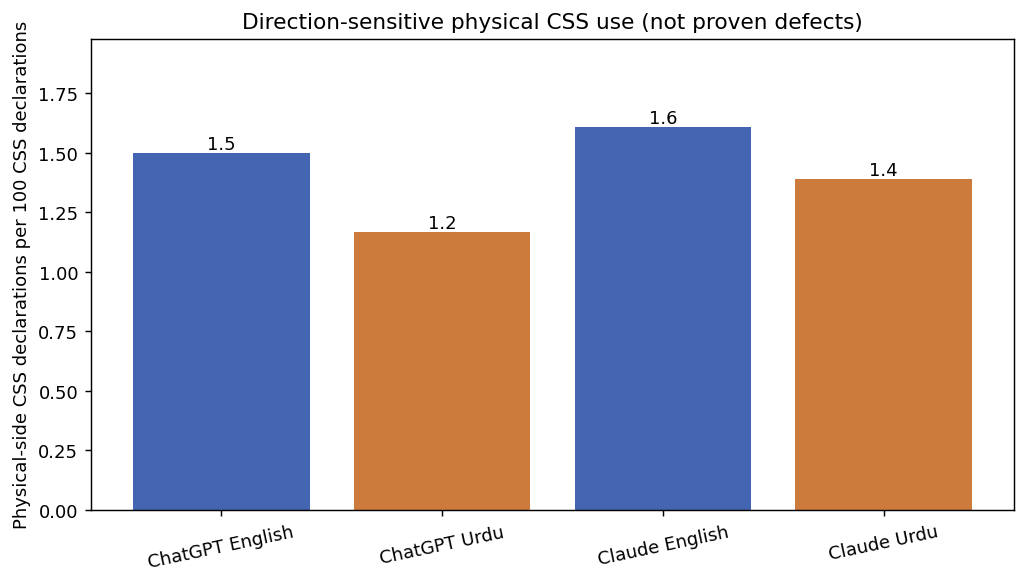

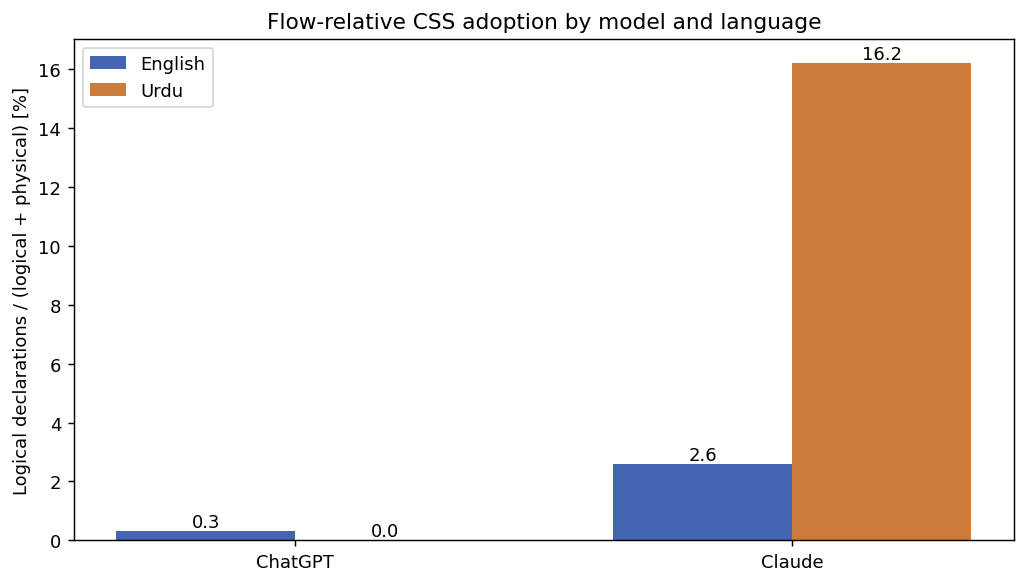

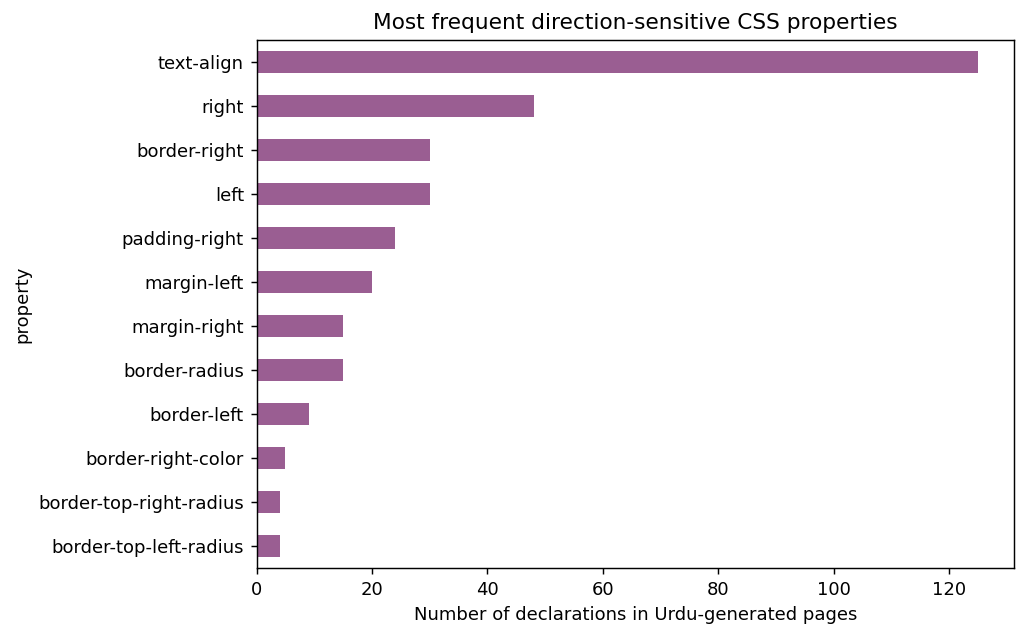

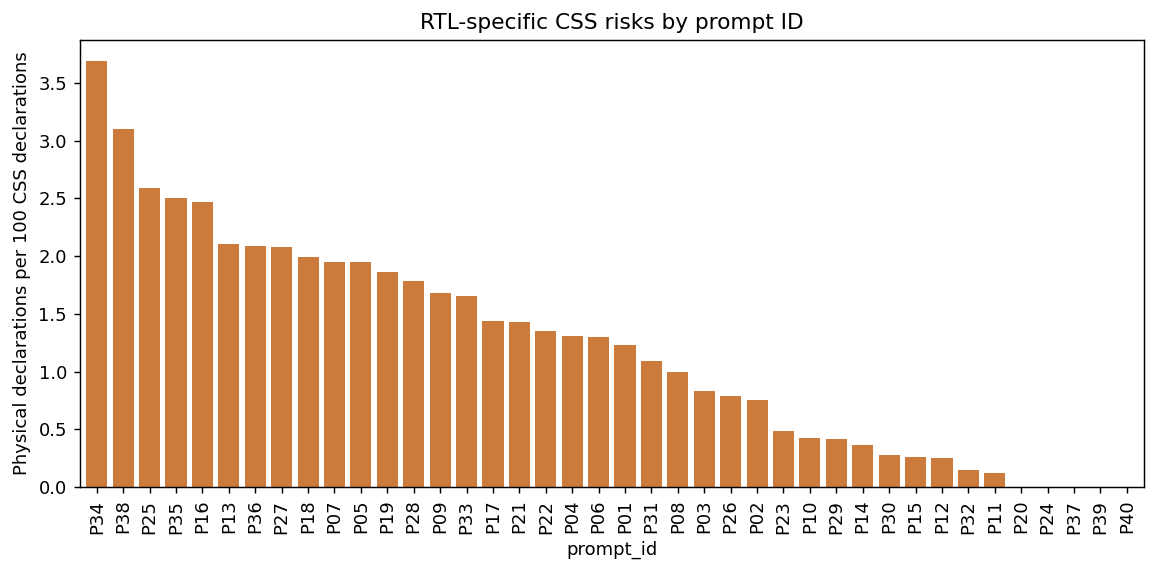

,prompt_id,model,html_file,selector,property,value
0,P34,chatgpt,urdu_rtl_study/P34/urdu/chatgpt/P34_urdu_chatg...,.close-btn,left,0
1,P22,chatgpt,urdu_rtl_study/P22/urdu/chatgpt/P22_run03.html,.growth span,margin-right,5px
2,P13,chatgpt,urdu_rtl_study/P13/urdu/chatgpt/P13_urdu_chatg...,.quote,border-right,4px solid #bd252d
3,P30,chatgpt,urdu_rtl_study/P30/urdu/chatgpt/p30-chatgpt-ru...,.level-tag,right,12px
4,P18,chatgpt,urdu_rtl_study/P18/urdu/chatgpt/P18_RUN01_chat...,.info-item,border-left,1px solid var(--border)
5,P05,chatgpt,urdu_rtl_study/P05/urdu/chatgpt/P05_urdu_chatg...,.section-title,border-right,4px solid #2563eb
6,P38,chatgpt,urdu_rtl_study/P38/urdu/chatgpt/P38_urdu_chatg...,.tab-button,border-radius,9px 9px 0 0
7,P19,chatgpt,urdu_rtl_study/P19/urdu/chatgpt/P19_RUN02_chat...,.nav-links,left,0
8,P09,chatgpt,urdu_rtl_study/P09/urdu/chatgpt/P01_urdu_chatg...,.section-title,border-right,5px solid #0e7490
9,P35,chatgpt,urdu_rtl_study/P35/urdu/chatgpt/P35_urdu_chatg...,.dropdown-menu a,padding-right,30px


In [11]:
from IPython.display import display, Image
from pathlib import Path
results_dir=Path(OUTPUT)
for fn in ['fig2_physical_css_density.png','fig3_logical_adoption.png',
           'fig4_top_physical_properties_urdu.png','fig5_physical_css_by_prompt.png']:
    display(Image(filename=str(results_dir / fn)))
css_review = css_cases[(css_cases.language == 'urdu') &
    (~css_cases.classification.isin(['logical','physical_value']))].copy()
css_review = css_review.sort_values(['prompt_id','html_file','property']).drop_duplicates('html_file')
sample = pd.concat([grp.sample(min(12,len(grp)), random_state=2027)
      for _,grp in css_review.groupby('model')], ignore_index=True)
for field in ['selector_matches_visible_element','physical_position_intentional',
              'actual_rtl_layout_defect','manual_notes']:
    sample[field]=''
sample.to_csv(results_dir/'sample_24_css_manual_review.csv',index=False,encoding='utf-8-sig')
display(sample[['prompt_id','model','html_file','selector','property','value']].head(12))

## Step 4 — Download the complete evaluation package

In [12]:
archive = shutil.make_archive('/content/RTL_Language_CSS_Evaluation_Results',
                              'zip', root_dir=OUTPUT)
print('Download:',archive)
files.download(archive)

Download: /content/RTL_Language_CSS_Evaluation_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Scientific interpretation
1. **Language of Parts:** a Latin-script string is not automatically English speech; WCAG 3.1.2 excludes proper names, technical terms and vernacular expressions. Test candidates in context and with assistive technology before recording a WCAG failure.
2. **CSS:** `left`, `right` and `text-align:right` can be intentional and correct in RTL. A physical CSS declaration is an *engineering review signal*, not a verified accessibility violation. Examine corresponding elements at multiple viewport widths.
3. **Coverage:** Browser DOM checks inspect the default page state only; externally loaded scripts and CSS were blocked. Full interactive states, icon mirroring, keyboard focus and screen-reader behavior require additional tests.

References: [W3C WCAG 3.1.2](https://www.w3.org/WAI/WCAG22/Understanding/language-of-parts), [W3C technique H58](https://www.w3.org/WAI/WCAG22/Techniques/html/H58) and [MDN logical CSS](https://developer.mozilla.org/en-US/docs/Web/CSS/Guides/Logical_properties_and_values).